# Taxis

In this task I work with the date and time of taxi trips in New York.

Columns I will use:

| Column | Meaning |
|---|---|
| pickup, dropoff | start and end time of the trip |
| distance | distance in miles |
| fare | price of the trip |
| tip | tip in dollars |
| payment | cash or credit card |

## Libraries

- pandas: tables and csv files
- numpy: arrays
- matplotlib: plots
- seaborn: only to download the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Loading the data

First I download the data, save it as csv, and read it again with pandas.

In [2]:
sns.load_dataset("taxis").to_csv("taxis.csv", index=False)

df = pd.read_csv("taxis.csv")
df.head()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


## DataFrame

In [3]:
df.shape

(6433, 14)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   pickup           6433 non-null   str    
 1   dropoff          6433 non-null   str    
 2   passengers       6433 non-null   int64  
 3   distance         6433 non-null   float64
 4   fare             6433 non-null   float64
 5   tip              6433 non-null   float64
 6   tolls            6433 non-null   float64
 7   total            6433 non-null   float64
 8   color            6433 non-null   str    
 9   payment          6389 non-null   str    
 10  pickup_zone      6407 non-null   str    
 11  dropoff_zone     6388 non-null   str    
 12  pickup_borough   6407 non-null   str    
 13  dropoff_borough  6388 non-null   str    
dtypes: float64(5), int64(1), str(8)
memory usage: 1.3 MB


In [5]:
df.isna().sum()

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

In [6]:
df.drop(columns=["pickup_zone", "dropoff_zone"], inplace=True)
df.dropna(inplace=True)
df.shape

(6341, 12)

In [7]:
df["payment"].value_counts()

payment
credit card    4546
cash           1795
Name: count, dtype: int64

Average tip for each payment type.

In [8]:
cash = df[df["payment"] == "cash"]
card = df[df["payment"] == "credit card"]

print("cash:", cash["tip"].mean())
print("credit card:", card["tip"].mean())

cash: 0.0
credit card: 2.751630004399472


In [9]:
df["pickup_borough"].value_counts()

pickup_borough
Manhattan    5226
Queens        638
Brooklyn      378
Bronx          99
Name: count, dtype: int64

## Datetime

`pickup` and `dropoff` are text, so I change them to datetime.

In [10]:
df["pickup"] = pd.to_datetime(df["pickup"])
df["dropoff"] = pd.to_datetime(df["dropoff"])
df[["pickup", "dropoff"]].dtypes

pickup     datetime64[us]
dropoff    datetime64[us]
dtype: object

Now I can get the hour and the day from the date, and find how long each trip was.

In [11]:
df["hour"] = df["pickup"].dt.hour
df["weekday"] = df["pickup"].dt.day_name()
df["duration_min"] = (df["dropoff"] - df["pickup"]).dt.total_seconds() / 60

df[["pickup", "hour", "weekday", "duration_min"]].head()

,pickup,hour,weekday,duration_min
0,2019-03-23 20:21:09,20,Saturday,6.250000
1,2019-03-04 16:11:55,16,Monday,7.083333
2,2019-03-27 17:53:01,17,Wednesday,7.400000
3,2019-03-10 01:23:59,1,Sunday,25.866667
4,2019-03-30 13:27:42,13,Saturday,9.533333


In [12]:
print(df["pickup"].min())
print(df["pickup"].max())

2019-02-28 23:29:03
2019-03-31 23:43:45


In [13]:
trips_hour = df["hour"].value_counts().sort_index()
trips_hour.head()

hour
0    198
1    109
2     97
3     65
4     55
Name: count, dtype: int64

In [14]:
df["weekday"].value_counts()

weekday
Friday       1091
Saturday     1028
Wednesday     958
Thursday      896
Sunday        857
Tuesday       811
Monday        700
Name: count, dtype: int64

## ndarray

In [15]:
fares = df["fare"].to_numpy()

print(fares.shape)
print(fares.ndim)
print(fares.mean())

(6341,)
1
12.887930925721495


In [16]:
cheap = fares[fares < 10]
print(len(cheap))

3377


In [17]:
data = df[["distance", "fare", "tip"]].to_numpy()
print(data.shape)
print(data.mean(axis=0))

(6341, 3)
[ 2.99770699 12.88793093  1.97270304]


## Numeric

In [18]:
df[["distance", "fare", "tip", "duration_min"]].describe()

,distance,fare,tip,duration_min
count,6341.000000,6341.000000,6341.000000,6341.000000
mean,2.997707,12.887931,1.972703,14.349183
std,3.719775,10.722249,2.361897,11.523417
min,0.000000,1.000000,0.000000,0.050000
25%,0.990000,6.500000,0.000000,6.533333
50%,1.650000,9.500000,1.750000,10.933333
75%,3.200000,15.000000,2.820000,18.483333
max,36.700000,150.000000,23.190000,107.666667


In [19]:
fare = df["fare"]

print("mean:", fare.mean())
print("median:", fare.median())
print("variance:", fare.var())
print("std:", fare.std())
print("skew:", fare.skew())
print("kurtosis:", fare.kurt())

mean: 12.887930925721495
median: 9.5
variance: 114.96663161731001
std: 10.722249373023834
skew: 2.606558389580325
kurtosis: 10.170827993181963


In [20]:
df[["distance", "fare", "tip", "duration_min"]].corr()

,distance,fare,tip,duration_min
distance,1.000000,0.947958,0.476980,0.822834
fare,0.947958,1.000000,0.487101,0.890197
tip,0.476980,0.487101,1.000000,0.405853
duration_min,0.822834,0.890197,0.405853,1.000000


## Plots

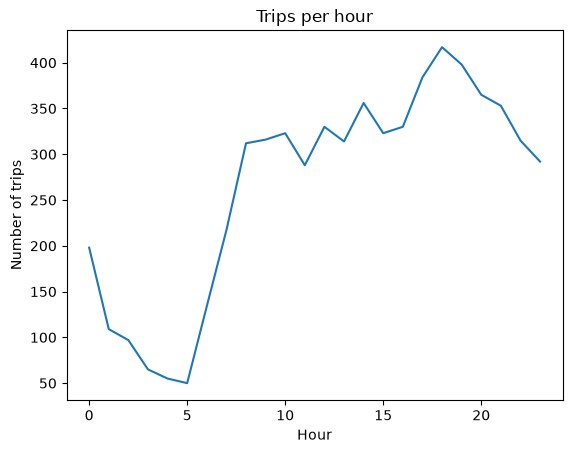

In [21]:
plt.plot(trips_hour.index, trips_hour.values)
plt.title("Trips per hour")
plt.xlabel("Hour")
plt.ylabel("Number of trips")
plt.show()

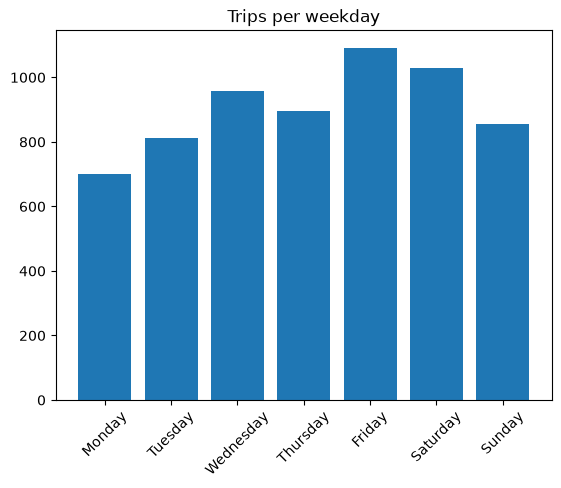

In [22]:
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
counts = df["weekday"].value_counts()

plt.bar(days, [counts[d] for d in days])
plt.title("Trips per weekday")
plt.xticks(rotation=45)
plt.show()

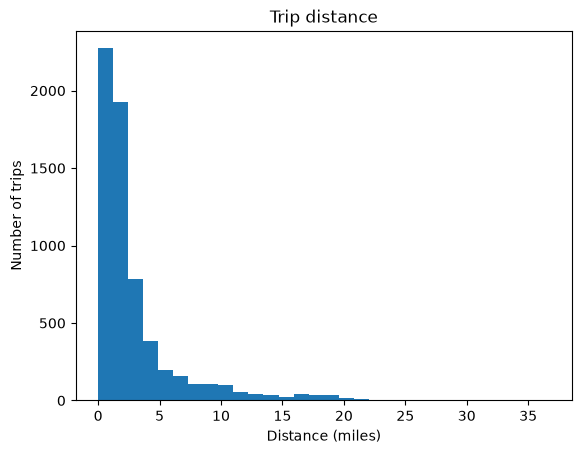

In [23]:
plt.hist(df["distance"], bins=30)
plt.title("Trip distance")
plt.xlabel("Distance (miles)")
plt.ylabel("Number of trips")
plt.show()

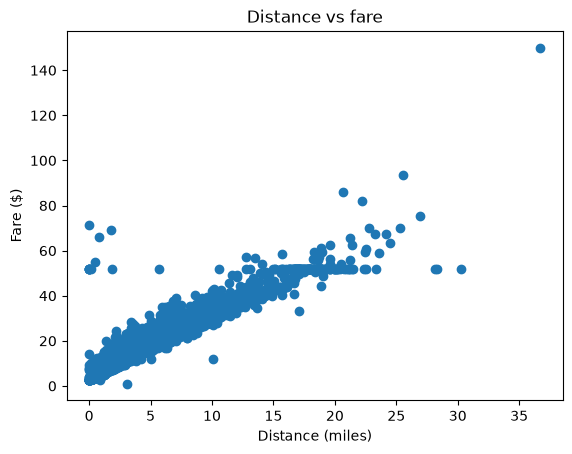

In [24]:
plt.scatter(df["distance"], df["fare"])
plt.title("Distance vs fare")
plt.xlabel("Distance (miles)")
plt.ylabel("Fare ($)")
plt.show()

## Conclusion

- The number of trips is different in each hour of the day.
- A longer trip has a higher fare.
- Most of the trips are short.